# COU07506-Digital Siginal Processing
## Week 2:Sampling, Aliasing and Quantazation

**Registration Number:** 240242444701
**Laboratory:** Lab 1A

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"]=(9,3.5)

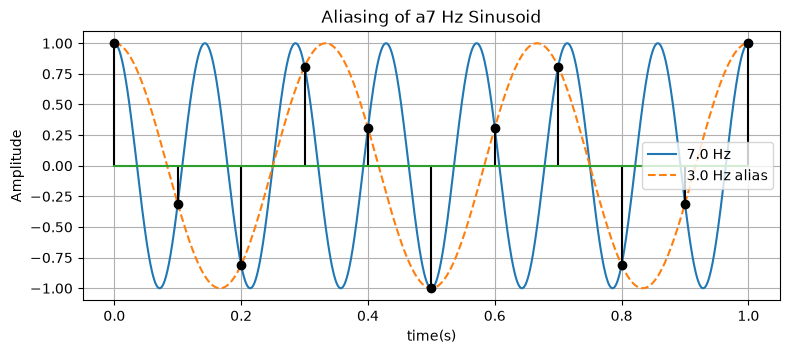

In [2]:
f0, fs=7.0, 10.0

t=np.linspace(0,1,2000)

n=np.arange(0, int(fs)+1)

tn=n/fs

f_alias=abs(f0-fs*round(f0/fs))

plt.plot(t,np.cos(2*np.pi*f0*t), label=f"{f0} Hz")

plt.plot(t,np.cos(2*np.pi*f_alias*t),   "--",
         label=f"{f_alias} Hz alias")

plt.stem(tn,np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt="")

plt.xlabel("time(s)")
plt.ylabel("Amplitude")
plt.title("Aliasing of a7 Hz Sinusoid")
plt.legend()
plt.grid()
plt.show()



In [3]:
sampling_rates=[12,14,20]

for fs in sampling_rates:
    f_alias=abs(f0-fs*round(f0/fs))

    print("Sampling frequency:",fs, "Hz")
    print("Alias frequency:",f_alias, "Hz")
    print("-----------------------")

Sampling frequency: 12 Hz
Alias frequency: 5.0 Hz
-----------------------
Sampling frequency: 14 Hz
Alias frequency: 7.0 Hz
-----------------------
Sampling frequency: 20 Hz
Alias frequency: 7.0 Hz
-----------------------


In [4]:
import os
from IPython.display import Audio,display

fname="my_voice.wav"

if os.path.exists(fname):
    fs, x=wavfile.read(fname)
    x=x.mean(axis=1) if x.ndim>1 else x.astype(float)
    x=x/np.max(np.abs(x))

else:
    fs=44100
    t=np.arange(0,3,1/fs)
    x=0.5*signal.chirp(t,200,3,15000)

print("Original sampling rate:",fs,"Hz")
print("Original signal duration:", len(x)/fs, "seconds")

Original sampling rate: 48000 Hz
Original signal duration: 6.784 seconds


In [5]:
for k in [2,4,8]:

    naive=x[::k]

    proper=signal.decimate(x,k,ftype="fir")

    new_fs=fs//k

    print("Decimation factor:",k)
    print("New sampling rate:",new_fs, "Hz")

    print("Naive version:")
    display(Audio(naive, rate=new_fs))

    print("Filtered version:")
    display(Audio(proper, rate=new_fs))

    print("-----------")

Decimation factor: 2
New sampling rate: 24000 Hz
Naive version:


Filtered version:


-----------
Decimation factor: 4
New sampling rate: 12000 Hz
Naive version:


Filtered version:


-----------
Decimation factor: 8
New sampling rate: 6000 Hz
Naive version:


Filtered version:


-----------


In [6]:
def uniform_quantizer(x,B):
    L=2**B
    xmin, xmax=-1,1

    Delta=(xmax-xmin)/L

    q_index=np.floor((x-xmin)/Delta)

    q_index=np.clip(q_index,0,L-1)

    xq=xmin+(q_index+0.5)*Delta

    return xq

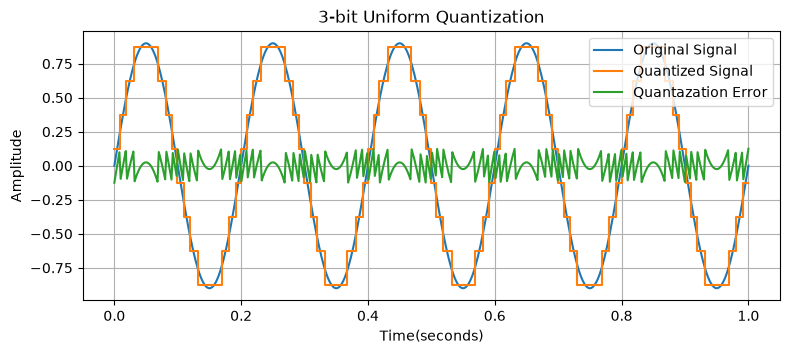

In [7]:
t=np.linspace(0,1,500)

x_test=0.9*np.sin(2*np.pi*5*t)

xq=uniform_quantizer(x_test,3)

error=x_test-xq

plt.plot(t,x_test,label="Original Signal")
plt.step(t,xq,where="mid",label="Quantized Signal")
plt.plot(t,error, label="Quantazation Error")

plt.xlabel("Time(seconds)")
plt.ylabel("Amplitude")
plt.title("3-bit Uniform Quantization")
plt.legend()
plt.grid()
plt.show()

In [8]:
bits=np.arange(2,17,2)

measured_sqnr=[]
theoretical_sqnr=[]

for B in bits:
    xq=uniform_quantizer(x_test,B)

    error=x_test-xq

    signal_power=np.mean(x_test**2)
    noise_power=np.mean(error**2)

    sqnr=10*np.log10(signal_power/noise_power)

    measured_sqnr.append(sqnr)

    theoretical_sqnr.append(6.02*B+1.76)

    print("Bits:",bits)
    print("Measured SQNR:",measured_sqnr)
    print("Theoretical SQNR:",theoretical_sqnr)

Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [np.float64(13.706772535374592)]
Theoretical SQNR: [np.float64(13.799999999999999)]
Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [np.float64(13.706772535374592), np.float64(24.42753077492309)]
Theoretical SQNR: [np.float64(13.799999999999999), np.float64(25.84)]
Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [np.float64(13.706772535374592), np.float64(24.42753077492309), np.float64(37.13229991901731)]
Theoretical SQNR: [np.float64(13.799999999999999), np.float64(25.84), np.float64(37.879999999999995)]
Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [np.float64(13.706772535374592), np.float64(24.42753077492309), np.float64(37.13229991901731), np.float64(48.81026321232686)]
Theoretical SQNR: [np.float64(13.799999999999999), np.float64(25.84), np.float64(37.879999999999995), np.float64(49.919999999999995)]
Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR: [np.float64(13.706772535374592), np.float64(24.42753077492309), np.float64(37.132299919017

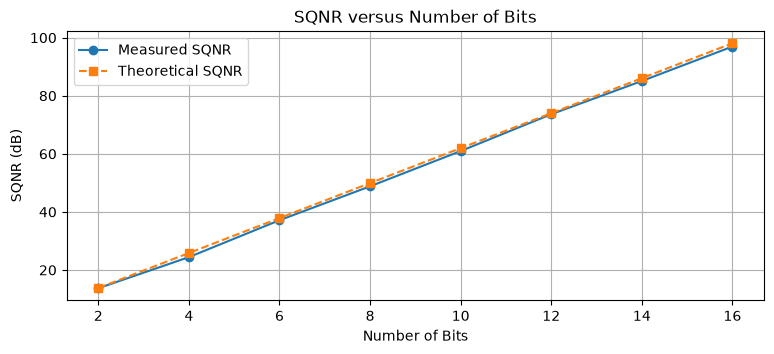

In [9]:
plt.plot(bits,measured_sqnr,"o-", label="Measured SQNR")

plt.plot(bits, theoretical_sqnr, "s--",
         label="Theoretical SQNR")

plt.xlabel("Number of Bits")
plt.ylabel("SQNR (dB)")
plt.title("SQNR versus Number of Bits")

plt.legend()
plt.grid()
plt.show()

In [10]:
for B in [4,8,12]:

    xq=uniform_quantizer(x,B)

    error=x-xq

    signal_power=np.mean(x**2)
    noise_power=np.mean(error**2)

    sqnr=10*np.log(signal_power/noise_power)

    print("Number of Bits:",B)
    print("SQNR:",round(sqnr,2),"dB")
    print("----------------")
    

Number of Bits: 4
SQNR: 29.31 dB
----------------
Number of Bits: 8
SQNR: 86.08 dB
----------------
Number of Bits: 12
SQNR: 141.66 dB
----------------


In [11]:
for B in [4,8,12]:

 xq=uniform_quantizer(x,B)

 print("Audio quantized using",B, "bits")

 display(Audio(xq, rate=fs))

 print("----------")





Audio quantized using 4 bits


----------
Audio quantized using 8 bits


----------
Audio quantized using 12 bits


----------


### Question 1

A 7Hz signal appear as a 3Hz signal whwn sampled at 10Hz due to aliasing.
This happen because the sampling frequency is lower than twice the original frequency , violating the Nyquist sampling criterion.
Therefore ,The sampled signal is interpreted as lower frequency of 3Hz

### Question 2

Aliasing cannot be removed after downsampling because high-frequency component has arleady folded into lower frequencies.
These unwanted frequency components overlap with the original signal frequencies, making it difficult to separate them.
Therefore,An ant-alising low pass filter must be applied before downsampling


### Question 3

WHen one bit is added to a uniform quantizer , the SQNR inreases by approximately 6dB.
THis is because adding one bit doubles the number of quantization levels ,reducing the quantization step size and quantization noise.
My measured results show an increasing SQNR as the number of bits increases, which agrees with the theoretical 6dB-per-bit rule approximately.

### Question 4

A suitable sampling rate is 10Hz(10 sample per second).
This allows the sensor to monitor tempereture change frequently.
Considering the maximum rate of change of 0.1 degree centigrade/s.

For quantization, the sensor has a measurement range of 100 degree centgrade and resolution of 0.01 degree centigrade

Number of levels required=100/0.01=10.000.

Using 2 power B >=10,000, the minimum number of bits required is 14 bits.

Therefore, a sampling rate of 10Hz and 14-bit quantizer are suitable choices.

## AI Use statement

ChatGPT was used as a learning assistant to understand DSP concepts,develop python code,and interpret the results of the laboratory exercises.
All code was excuted and checked using Jupyter Notebook, and the results were reviewed.